# 01 Data audit and experiment check

**Project question.** With a limited marketing budget, which customers should receive an SMS so that it creates the most additional purchases?

**This notebook.** Every answer to the project question relies on a fair SMS experiment. This notebook checks the data and the experiment, and fixes what has to be fixed before modelling.

**Summary.** The data is consistent once purchases are read as item rows and baskets are counted correctly. Clients who received the SMS and clients who did not look the same on everything known before the SMS, so the experiment can be trusted. One client field contained information from after the SMS and was cut back to the decision moment.

**Research question.** Can the X5 data be analysed as a randomized experiment, and what has to be fixed before modelling?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from x5uplift import plotting as P
from x5uplift.audit_utils import srm_chisquare
from x5uplift.config import AGE_MAX, AGE_MIN, CUTOFF, EXPECTED_TREATMENT_SHARE, FEATURES_PATH, SPLITS_PATH
from x5uplift.features import connect
from x5uplift.splits import make_splits

pd.set_option("display.width", 140)
P.set_style()
con = connect()  # DuckDB views: clients, train, purchases, products
q = lambda sql: con.execute(sql).df()

q("""
SELECT 'clients' AS table_name, COUNT(*) AS n_rows FROM clients
UNION ALL SELECT 'train', COUNT(*) FROM train
UNION ALL SELECT 'purchases', COUNT(*) FROM purchases
UNION ALL SELECT 'products', COUNT(*) FROM products
""")

,table_name,n_rows
0,clients,400162
1,train,200039
2,purchases,45786568
3,products,43038


## 1. What the data contains

Row counts match the documentation. `train` is the experiment: who got the SMS (`treatment_flg`) and who bought afterwards (`target`).

In [2]:
q("""
WITH t AS (
    SELECT transaction_id, COUNT(*) AS n_items, COUNT(DISTINCT client_id) AS n_clients,
           COUNT(DISTINCT purchase_sum) AS n_sums, MAX(purchase_sum) AS basket_sum,
           SUM(trn_sum_from_iss) AS items_sum
    FROM purchases
    GROUP BY transaction_id
)
SELECT
    COUNT(*)                                                 AS n_transactions,
    AVG(n_items)                                             AS avg_items,
    SUM(CASE WHEN n_clients > 1 THEN 1 ELSE 0 END)           AS n_shared_by_clients,
    AVG(CASE WHEN n_sums > 1 THEN 1 ELSE 0 END)              AS share_varying_basket_sum,
    AVG(CASE WHEN ABS(items_sum - basket_sum) <= 1 THEN 1 ELSE 0 END) AS share_items_add_up
FROM t
""").T

,0
n_transactions,8.045201e+06
avg_items,5.691165e+00
n_shared_by_clients,2.800000e+01
share_varying_basket_sum,3.480336e-06
share_items_add_up,8.719256e-01


Purchases are item rows: 8,045,201 baskets with 5.7 items on average. `purchase_sum` and the point columns are basket totals repeated on every row, so spend is taken once per basket. 28 transaction ids are shared by two clients, so a basket is keyed by (client, transaction). Item amounts add up to the basket total in 87% of baskets.

In [3]:
q("""
SELECT
    COUNT(*)                                     AS n_products,
    COUNT(DISTINCT level_2)                      AS n_level_2,
    COUNT(DISTINCT level_4)                      AS n_level_4,
    (SELECT COUNT(DISTINCT product_id) FROM purchases
     WHERE product_id NOT IN (SELECT product_id FROM products)) AS n_purchased_missing,
    AVG(is_own_trademark)                        AS share_own_brand,
    AVG(is_alcohol)                              AS share_alcohol
FROM products
""").T

,0
n_products,43038.000000
n_level_2,42.000000
n_level_4,790.000000
n_purchased_missing,0.000000
share_own_brand,0.035178
share_alcohol,0.055602


All purchased products are in the product table. Category ids are hashed, so categories can be used but not named.

In [4]:
q("""
SELECT
    QUANTILE_CONT(product_quantity, [0.5, 0.99, 0.9999])                         AS qty_q50_q99_q9999,
    AVG(CASE WHEN product_quantity = 0 THEN 1 ELSE 0 END)                        AS share_zero_qty,
    AVG(CASE WHEN product_quantity <> FLOOR(product_quantity) THEN 1 ELSE 0 END) AS share_fractional_qty
FROM purchases
""").T

,0
qty_q50_q99_q9999,"[1.0, 5.0, 30.0]"
share_zero_qty,0.059128
share_fractional_qty,0.0


6% of item rows have quantity 0 and none is fractional, although a grocer sells weighed goods. Quantity is not used.

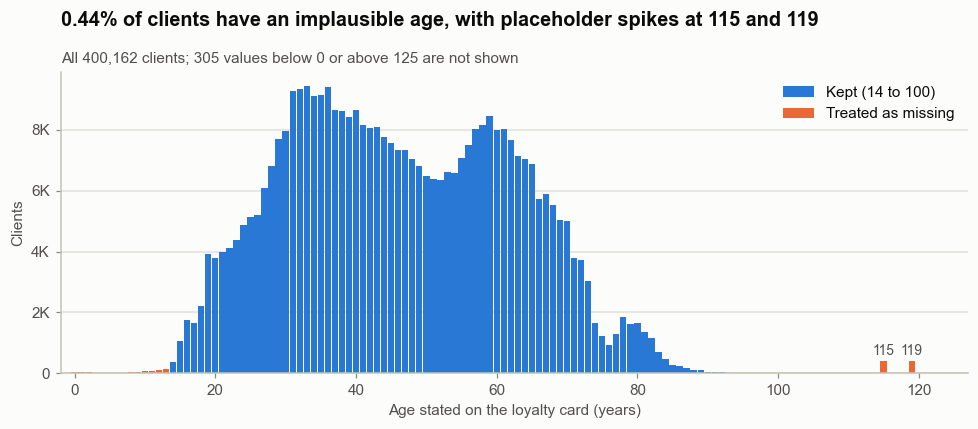

In [5]:
ages = q("SELECT age, COUNT(*) AS n FROM clients WHERE age BETWEEN 0 AND 125 GROUP BY age ORDER BY age")
n_hidden, n_clients = q("SELECT COUNT(*) FILTER (WHERE age < 0 OR age > 125), COUNT(*) FROM clients").iloc[0]
bad = ~ages["age"].between(AGE_MIN, AGE_MAX)
pct_bad = 100 * (ages.loc[bad, "n"].sum() + n_hidden) / n_clients
spikes = ages[ages["age"] > AGE_MAX].nlargest(2, "n").sort_values("age")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(ages.loc[~bad, "age"], ages.loc[~bad, "n"], width=0.9, color=P.BLUE, label=f"Kept ({AGE_MIN} to {AGE_MAX})")
ax.bar(ages.loc[bad, "age"], ages.loc[bad, "n"], width=0.9, color=P.ORANGE, label="Treated as missing")
for a, v in spikes[["age", "n"]].itertuples(index=False):
    ax.annotate(f"{a}", xy=(a, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=P.INK_2)
ax.set(xlim=(-2, 127), xlabel="Age stated on the loyalty card (years)", ylabel="Clients")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}K" if v >= 1000 else f"{v:.0f}")
ax.legend(loc="upper right")
P.titles(ax, f"{pct_bad:.2f}% of clients have an implausible age, with placeholder spikes at "
             f"{spikes['age'].iloc[0]} and {spikes['age'].iloc[1]}",
         f"All {n_clients:,} clients; {n_hidden:,} values below 0 or above 125 are not shown")
fig.tight_layout()
P.save(fig, "01_age_cleaning")
plt.show()

Ages outside 14 to 100 are treated as missing and flagged. The spikes at 115 and 119 look like default values.

## 2. When was the decision made?

The SMS date is not given. The history ends at 2019-03-18 23:40:03 and is described as the history before the campaign, so this is the decision moment (`CUTOFF`). Every model input must be known by then.

In [6]:
check = q(f"""
SELECT (SELECT MAX(transaction_datetime) FROM purchases) = TIMESTAMP '{CUTOFF}'      AS cutoff_is_history_end,
       (SELECT COUNT(*) FROM clients WHERE first_issue_date > TIMESTAMP '{CUTOFF}') AS cards_after_cutoff
""")
assert check.loc[0, "cutoff_is_history_end"] and check.loc[0, "cards_after_cutoff"] == 0

If the SMS had been sent inside the history, the treatment group would already shop more in its last days.

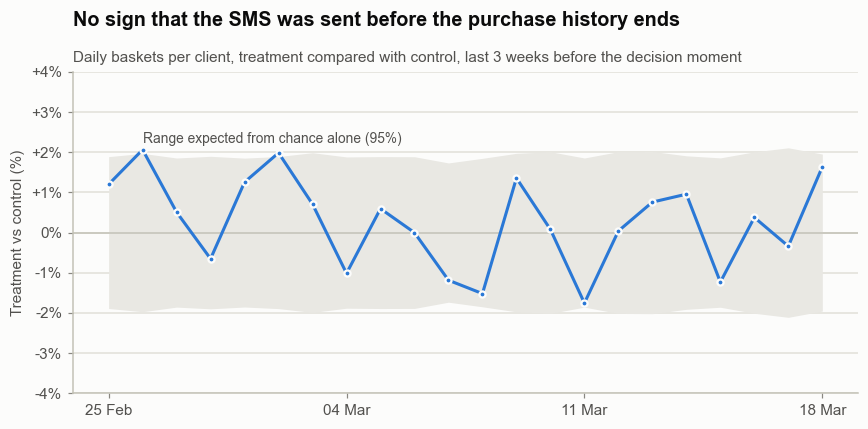

In [7]:
daily = q("""
SELECT CAST(p.transaction_datetime AS DATE) AS day, t.treatment_flg, COUNT(DISTINCT p.transaction_id) AS n_txn
FROM purchases AS p JOIN train AS t USING (client_id)
WHERE p.transaction_datetime >= TIMESTAMP '2019-02-25'
GROUP BY 1, 2
""").pivot(index="day", columns="treatment_flg", values="n_txn")
n_group = q("SELECT treatment_flg, COUNT(*) AS n FROM train GROUP BY 1").set_index("treatment_flg")["n"]
diff_pct = ((daily[1] / n_group[1]) / (daily[0] / n_group[0]) - 1) * 100
band_pct = 1.96 * np.sqrt(1 / daily[0] + 1 / daily[1]) * 100  # 95% chance range (Poisson)

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(daily.index, -band_pct, band_pct, color=P.NEUTRAL_FILL, linewidth=0)
ax.axhline(0, color=P.AXIS, linewidth=1)
ax.plot(daily.index, diff_pct, color=P.TREATMENT, marker="o", markersize=4, markeredgecolor=P.SURFACE, markeredgewidth=1.5)
ax.text(daily.index[1], band_pct.iloc[1] + 0.25, "Range expected from chance alone (95%)", fontsize=9, color=P.INK_2)
ax.set(ylim=(-4, 4), ylabel="Treatment vs control (%)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%" if v else "0%")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
P.titles(ax, "No sign that the SMS was sent before the purchase history ends",
         "Daily baskets per client, treatment compared with control, last 3 weeks before the decision moment")
fig.tight_layout()
P.save(fig, "01_sms_timing_check")
plt.show()

The daily difference stays within the chance range (about ±2%) and does not rise at the end. An SMS in the last day or two with a small effect cannot be ruled out.

## 3. A leak: the first redemption date

`first_redeem_date` (first time a client spent points) comes from a clients table exported months after the campaign.

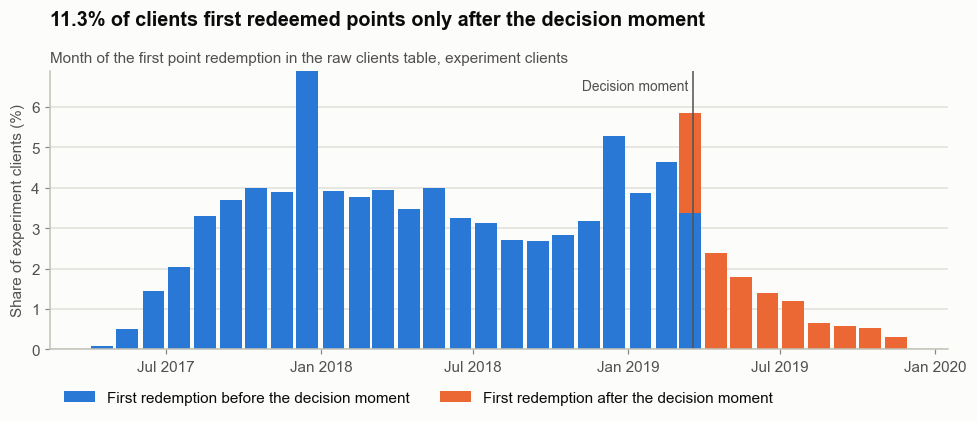

In [8]:
redeem = q(f"""
SELECT DATE_TRUNC('month', c.first_redeem_date) AS month,
       c.first_redeem_date > TIMESTAMP '{CUTOFF}' AS after_cutoff,
       COUNT(*) * 100.0 / (SELECT COUNT(*) FROM train) AS pct
FROM train AS t JOIN clients AS c USING (client_id)
WHERE c.first_redeem_date IS NOT NULL
GROUP BY 1, 2
""").pivot(index="month", columns="after_cutoff", values="pct").fillna(0).sort_index()
x = redeem.index + pd.Timedelta(days=15)  # centre bars inside their month

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x, redeem[False], width=26, color=P.BLUE, label="First redemption before the decision moment")
ax.bar(x, redeem[True], width=26, bottom=redeem[False], color=P.ORANGE, label="First redemption after the decision moment")
ax.axvline(pd.Timestamp(CUTOFF), color=P.INK_2, linewidth=1)
ax.text(pd.Timestamp(CUTOFF), ax.get_ylim()[1] * 0.97, "Decision moment ", ha="right", va="top", fontsize=9, color=P.INK_2)
ax.set_ylabel("Share of experiment clients (%)")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=2)
P.titles(ax, f"{redeem[True].sum():.1f}% of clients first redeemed points only after the decision moment",
         "Month of the first point redemption in the raw clients table, experiment clients")
fig.tight_layout()
P.save(fig, "01_redeem_date_leak")
plt.show()

In [9]:
q(f"""
SELECT t.treatment_flg,
       AVG(CASE WHEN c.first_redeem_date >  TIMESTAMP '{CUTOFF}' THEN 1 ELSE 0 END) AS share_first_redeem_after,
       AVG(CASE WHEN c.first_redeem_date <= TIMESTAMP '{CUTOFF}' THEN 1 ELSE 0 END) AS share_first_redeem_before
FROM train AS t JOIN clients AS c USING (client_id)
GROUP BY 1 ORDER BY 1
""")

,treatment_flg,share_first_redeem_after,share_first_redeem_before
0,0,0.111036,0.797937
1,1,0.114922,0.800682


After the decision moment, 11.49% of the treatment group redeemed for the first time against 11.10% of control (about 2.8 standard errors): the SMS changed this column. Before it, the groups match (80.07% and 79.79%). Used raw, the column would leak the outcome into models and bias the A/B analysis. **Fix:** dates after the decision moment count as "not redeemed yet" (`features.py`). A standardized difference check alone would have missed this leak (difference of about 0.02 SD).

## 4. Was the experiment randomized?

In [10]:
n_group = q("SELECT treatment_flg, COUNT(*) AS n FROM train GROUP BY 1").set_index("treatment_flg")["n"]
chi2, p = srm_chisquare(n_group[1], n_group[0], EXPECTED_TREATMENT_SHARE)
print(f"Control {n_group[0]:,}, treatment {n_group[1]:,}; sample ratio mismatch test: chi2 = {chi2:.3f}, p = {p:.3f}")

Control 100,058, treatment 99,981; sample ratio mismatch test: chi2 = 0.030, p = 0.863


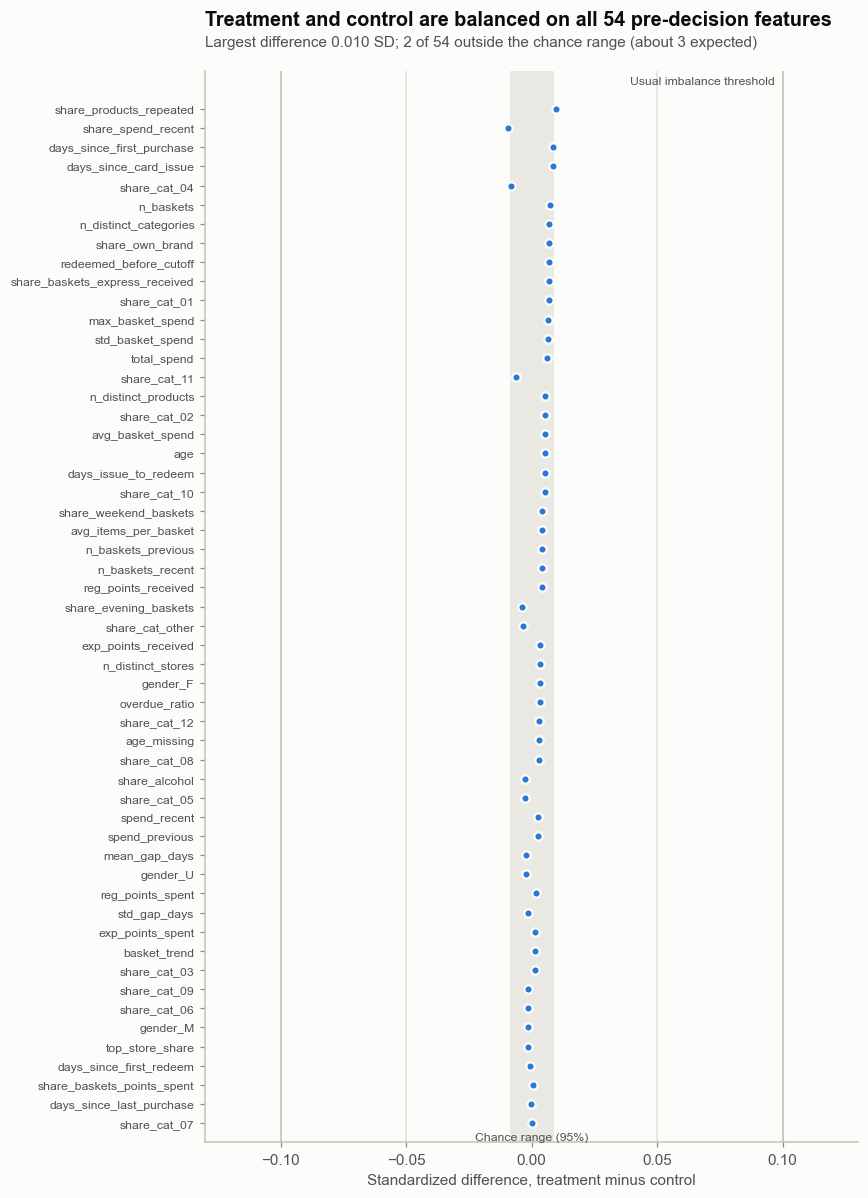

In [11]:
exp = q("SELECT client_id, treatment_flg FROM train").merge(pd.read_parquet(FEATURES_PATH), on="client_id")
X = pd.get_dummies(exp.drop(columns=["client_id", "treatment_flg"]), columns=["gender"], dtype=float)
g = X.groupby(exp["treatment_flg"])
smd = ((g.mean().loc[1] - g.mean().loc[0]) / np.sqrt((g.var().loc[1] + g.var().loc[0]) / 2)).sort_values(key=abs)
chance = 1.96 * np.sqrt(1 / n_group[1] + 1 / n_group[0])  # 95% range of an SMD under no difference

fig, ax = plt.subplots(figsize=(8, 11))
y = np.arange(len(smd))
ax.axvspan(-chance, chance, color=P.NEUTRAL_FILL, linewidth=0)
for xline in (-0.1, 0.1):
    ax.axvline(xline, color=P.AXIS, linewidth=1)
ax.scatter(smd.values, y, s=30, color=P.TREATMENT, edgecolor=P.SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(y, smd.index, fontsize=8)
ax.set(xlim=(-0.13, 0.13), ylim=(-1, len(smd) + 1), xlabel="Standardized difference, treatment minus control")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.text(0.097, len(smd) + 0.3, "Usual imbalance threshold", ha="right", fontsize=8, color=P.INK_2)
ax.text(0, -0.9, "Chance range (95%)", ha="center", fontsize=8, color=P.INK_2)
verdict = "are balanced" if smd.abs().max() < 0.1 else "are NOT balanced"
P.titles(ax, f"Treatment and control {verdict} on all {len(smd)} pre-decision features",
         f"Largest difference {smd.abs().max():.3f} SD; {(smd.abs() > chance).sum()} of {len(smd)} outside the "
         f"chance range (about {0.05 * len(smd):.0f} expected)")
fig.tight_layout()
P.save(fig, "01_balance")
plt.show()

Group sizes match a 50/50 design (p = 0.86). The largest feature difference is 0.010 SD, a tenth of the usual 0.1 threshold, and 2 of 54 features fall outside the chance range where about 3 are expected.

## 5. Splitting the labelled data

30% of the labelled clients is a test set that stays untouched until notebook 06. The other 70% is split into 5 folds for cross fitting. Both are stratified by treatment and outcome.

In [12]:
labeled = q("SELECT client_id, treatment_flg, target FROM train")
splits = make_splits(labeled)
assert splits.equals(make_splits(labeled)), "split is not reproducible"
splits.to_parquet(SPLITS_PATH, index=False)
part = np.where(splits["is_test"], "test", "fold_" + splits["fold"].astype(str))
splits.assign(part=part).groupby("part").agg(
    n_clients=("client_id", "size"), treatment_share=("treatment_flg", "mean"), target_rate=("target", "mean")
).round(4)

,n_clients,treatment_share,target_rate
part,,,
fold_0,28007,0.4998,0.6199
fold_1,28007,0.4998,0.6199
fold_2,28005,0.4998,0.6199
fold_3,28005,0.4998,0.6199
fold_4,28003,0.4998,0.6199
test,60012,0.4998,0.6199


## Conclusion

**Answer.** Yes. Assignment was random in practice and the groups are balanced on all 54 features known before the SMS, so causal statements about the SMS can be made inside this experiment.

**Fixed before modelling:** spend is counted once per basket; `first_redeem_date` is cut at the decision moment; implausible ages are missing; quantity is not used.

**Open:** the time window behind `target` is not documented; age and gender may have been updated after the campaign.

**Next step.** Notebook 02 describes the clients and builds segments.